Local repository copy. Open this notebook in Cursor/Jupyter and run cells from top to bottom.
No Git clone is needed: the data is already in `data/`.


# Data exploration: auto theft hotspot forecast
Group 4, Section 401 | Fatima, Step 1

Open from the local project folder in Cursor or Jupyter; no clone/download required.
This notebook reads `data/auto_theft.csv` and Sean's `data/panel.csv`,
loads the completed `data/data_dictionary.csv`, and saves charts under `data/charts/`.
Findings and figures are included in the group Word report.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data/auto_theft.csv").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "data/auto_theft.csv").is_file():
    raise FileNotFoundError("Open the notebook in the COMP309 project or its src/ folder")
DATA_FILE = str(PROJECT_ROOT / "data/auto_theft.csv")
REPO = str(PROJECT_ROOT)
CHARTS_DIR = PROJECT_ROOT / "data/charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(CHARTS_DIR / f"{name}.png", dpi=150)
    plt.show()
    plt.close("all")

MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

## 1. Load and describe the data

In [3]:
# utf-8-sig strips the hidden byte-order mark at the start of the file
df = pd.read_csv(DATA_FILE, encoding="utf-8-sig")

print("Rows and columns:", df.shape)
print("Unique events (EVENT_UNIQUE_ID):", df["EVENT_UNIQUE_ID"].nunique())
print("Rows that are exact copies of another row (ignoring OBJECTID):",
      df.drop(columns="OBJECTID").duplicated().sum())
df.head()

Rows and columns: (82746, 31)
Unique events (EVENT_UNIQUE_ID): 74604
Rows that are exact copies of another row (ignoring OBJECTID): 8142


,OBJECTID,EVENT_UNIQUE_ID,REPORT_DATE,OCC_DATE,REPORT_YEAR,REPORT_MONTH,REPORT_DAY,REPORT_DOY,REPORT_DOW,REPORT_HOUR,OCC_YEAR,OCC_MONTH,OCC_DAY,OCC_DOY,OCC_DOW,OCC_HOUR,DIVISION,LOCATION_TYPE,PREMISES_TYPE,UCR_CODE,UCR_EXT,OFFENCE,CSI_CATEGORY,HOOD_158,NEIGHBOURHOOD_158,HOOD_140,NEIGHBOURHOOD_140,LONG_WGS84,LAT_WGS84,x,y
0,1,GO-20141262837,1/1/2014 5:00:00 AM,12/25/2013 5:00:00 AM,2014,January,1,1,Wednesday,15,2013.0,December,25.0,359.0,Wednesday,0,D22,"Parking Lots (Apt., Commercial Or Non-Commercial)",Outside,2135,210,Theft Of Motor Vehicle,Auto Theft,159,Etobicoke City Centre (159),014,Islington-City Centre West (14),-79.529692,43.618988,-8.853205e+06,5.406668e+06
1,2,GO-20141262914,1/1/2014 5:00:00 AM,1/1/2014 5:00:00 AM,2014,January,1,1,Wednesday,15,2014.0,January,1.0,1.0,Wednesday,15,D43,"Streets, Roads, Highways (Bicycle Path, Privat...",Outside,2135,210,Theft Of Motor Vehicle,Auto Theft,123,Cliffcrest (123),123,Cliffcrest (123),-79.236119,43.721827,-8.820524e+06,5.422495e+06
2,3,GO-20141263217,1/1/2014 5:00:00 AM,12/31/2013 5:00:00 AM,2014,January,1,1,Wednesday,16,2013.0,December,31.0,365.0,Tuesday,17,D33,"Apartment (Rooming House, Condo)",Apartment,2135,210,Theft Of Motor Vehicle,Auto Theft,043,Victoria Village (43),043,Victoria Village (43),-79.306754,43.734654,-8.828387e+06,5.424471e+06
3,4,GO-20141265795,1/2/2014 5:00:00 AM,1/1/2014 5:00:00 AM,2014,January,2,2,Thursday,7,2014.0,January,1.0,1.0,Wednesday,19,D23,"Parking Lots (Apt., Commercial Or Non-Commercial)",Outside,2135,210,Theft Of Motor Vehicle,Auto Theft,009,Edenbridge-Humber Valley (9),009,Edenbridge-Humber Valley (9),-79.512451,43.685520,-8.851286e+06,5.416904e+06
4,5,GO-20141265947,1/2/2014 5:00:00 AM,1/1/2014 5:00:00 AM,2014,January,2,2,Thursday,8,2014.0,January,1.0,1.0,Wednesday,15,D23,"Parking Lots (Apt., Commercial Or Non-Commercial)",Outside,2135,210,Theft Of Motor Vehicle,Auto Theft,002,Mount Olive-Silverstone-Jamestown (2),002,Mount Olive-Silverstone-Jamestown (2),-79.595344,43.744299,-8.860513e+06,5.425957e+06


In [4]:
# Clean the text columns: day-of-week values come with trailing spaces ("Wednesday ")
for col in ["OCC_DOW", "REPORT_DOW", "OCC_MONTH", "REPORT_MONTH"]:
    df[col] = df[col].str.strip()

# From here on we work with one row per event
events = df.drop_duplicates("EVENT_UNIQUE_ID").copy()
print("Events after removing duplicates:", len(events))

df.dtypes

Events after removing duplicates: 74604


,0
OBJECTID,int64
EVENT_UNIQUE_ID,object
REPORT_DATE,object
OCC_DATE,object
REPORT_YEAR,int64
REPORT_MONTH,object
REPORT_DAY,int64
REPORT_DOY,int64
REPORT_DOW,object
REPORT_HOUR,int64


In [5]:
# Fatima's completed dictionary, 31 original source fields.
dictionary = pd.read_csv(PROJECT_ROOT / 'data/data_dictionary.csv')
print('Dictionary columns:',len(dictionary))
display(dictionary.head())


,column,type,distinct_values,blank_rows,example,description,used_in_project
0,OBJECTID,int64,82746,0,1,,
1,EVENT_UNIQUE_ID,object,74604,0,GO-20141262837,,
2,REPORT_DATE,object,4656,0,1/1/2014 5:00:00 AM,,
3,OCC_DATE,object,4710,0,12/25/2013 5:00:00 AM,,
4,REPORT_YEAR,int64,13,0,2014,,
5,REPORT_MONTH,object,12,0,January,,
6,REPORT_DAY,int64,31,0,1,,
7,REPORT_DOY,int64,366,0,1,,
8,REPORT_DOW,object,7,0,Wednesday,,
9,REPORT_HOUR,int64,24,0,15,,


### Findings: the dataset

**Dataset paragraph (for the report).** The data is the Auto Theft category of the Toronto Police Service's Community Safety Indicators (CSI) open dataset, downloaded from the Public Safety Data Portal on November 12th, 2026. The file has 82,746 rows and 31 columns. Auto theft is recorded at the offence and vehicle level, so one occurrence number can appear on several rows: the 82,746 rows contain 74,604 unique events (EVENT_UNIQUE_ID), and 8,142 rows are exact copies of another row apart from the row number. Every row is a "Theft Of Motor Vehicle". Reports run from January 2014 to 30 September 2026, and 57 events have occurrence dates before 2014 (as early as 2000), which means they were reported late. Locations are offset to the nearest intersection, the data is preliminary and may not be fully verified, and the file has no vehicle details (make, model, colour, value) and no recovery status.

**Data dictionary.** `data/data_dictionary.csv` describes all 31 columns. 28 descriptions come from the portal documentation. OBJECTID (a row number) and x and y (map coordinates in a projected system, likely metres) are not documented. Only six columns feed the model (EVENT_UNIQUE_ID, OCC_DATE, HOOD_158, NEIGHBOURHOOD_158, PREMISES_TYPE and OCC_HOUR). The rest are dropped, checked, or used only for exploration.

## 2. Statistics and correlations

In [6]:
num_cols = ["OCC_YEAR", "OCC_DAY", "OCC_DOY", "OCC_HOUR", "REPORT_YEAR", "REPORT_HOUR",
            "LAT_WGS84", "LONG_WGS84"]
events[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
OCC_YEAR,74600.0,2021.05,3.40,2000.00,2019.00,2022.00,2024.00,2026.00
OCC_DAY,74600.0,15.61,8.76,1.00,8.00,16.00,23.00,31.00
OCC_DOY,74600.0,183.97,104.04,1.00,94.00,185.00,273.00,366.00
OCC_HOUR,74604.0,13.82,7.58,0.00,7.00,16.00,20.00,23.00
REPORT_YEAR,74604.0,2021.07,3.39,2014.00,2019.00,2022.00,2024.00,2026.00
REPORT_HOUR,74604.0,11.48,5.52,0.00,7.00,10.00,16.00,23.00
LAT_WGS84,74604.0,43.25,4.53,0.00,43.68,43.72,43.76,43.85
LONG_WGS84,74604.0,-78.56,8.23,-79.64,-79.52,-79.43,-79.33,0.00


In [7]:
for col in ["DIVISION", "PREMISES_TYPE", "OCC_DOW", "OCC_MONTH"]:
    print(f"\n{col}  ({events[col].nunique()} distinct values)")
    print(events[col].value_counts(dropna=False).head(10))

print("\nLOCATION_TYPE distinct values:", events["LOCATION_TYPE"].nunique())
print("NEIGHBOURHOOD_158 distinct values:", events["NEIGHBOURHOOD_158"].nunique())


DIVISION  (18 distinct values)
DIVISION
D23    10030
D32     8299
D31     7256
D22     7100
D42     6277
D41     4636
D43     4607
D33     4223
D53     3911
D12     3763
Name: count, dtype: int64

PREMISES_TYPE  (7 distinct values)
PREMISES_TYPE
Outside        41248
House          22512
Commercial      5787
Apartment       2455
Other           2239
Transit          266
Educational       97
Name: count, dtype: int64

OCC_DOW  (7 distinct values)
OCC_DOW
Thursday     11468
Wednesday    11265
Tuesday      11242
Friday       10848
Monday       10706
Sunday        9619
Saturday      9452
NaN              4
Name: count, dtype: int64

OCC_MONTH  (12 distinct values)
OCC_MONTH
September    6546
August       6498
November     6463
July         6388
May          6365
October      6340
March        6339
June         6317
January      6120
April        6051
Name: count, dtype: int64

LOCATION_TYPE distinct values: 42
NEIGHBOURHOOD_158 distinct values: 159


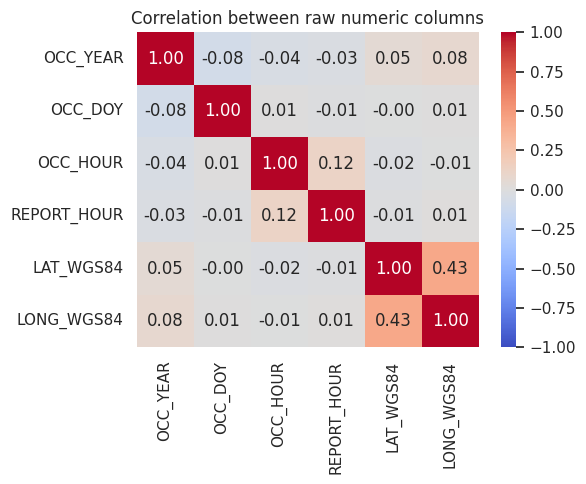

In [8]:
# Correlations between the raw numeric columns (rows with unknown location or date left out)
clean = events[(events["LAT_WGS84"] != 0) & (events["LONG_WGS84"] != 0)].dropna(subset=["OCC_YEAR"])
corr = clean[["OCC_YEAR", "OCC_DOY", "OCC_HOUR", "REPORT_HOUR", "LAT_WGS84", "LONG_WGS84"]].corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between raw numeric columns")
save("01_correlation_raw_numeric")

### Findings: statistics and correlations

- **Most thefts are recent.** OCC_YEAR runs from 2000 to 2026, but the median is 2022 and about 75% of events occurred in 2019 or later.
- **Thefts lean towards the evening and night.** The mean hour is 13.8, the median is 16 and the 75th percentile is 20.
- **Thefts are reported earlier in the day than they happen.** The median report hour is 10 and the median occurrence hour is 16, which fits a car taken in the evening or overnight being noticed the next morning.
- **Unknown locations are coded as 0.** The minimum latitude is 0 and the maximum longitude is 0, which drags the mean latitude down to 43.25 and the mean longitude up to -78.56 (real values are about 43.6 to 43.85 and -79.6 to -79.1). These 810 events must be removed before any location analysis.
- **The raw columns barely correlate.** Every correlation is weak (0.12 or less in size), with one exception: latitude and longitude at 0.43, which only reflects the city's diagonal shape. Time and place fields hold no simple linear signal on their own.

**Why it matters:** the useful relationships for this project appear once thefts are counted per neighbourhood per month (section 5).

## 3. Missing and unknown data

Truly blank values (events):


,blank_events
OCC_YEAR,4
OCC_MONTH,4
OCC_DAY,4
OCC_DOY,4
OCC_DOW,4
LOCATION_TYPE,13


,events,percent_of_events
Neighbourhood is NSA (unknown),847,1.14
Division is NSA (unknown),362,0.49
Latitude or longitude is 0,810,1.09
Occurrence year before 2014,57,0.08
No occurrence date,4,0.01
Blank location type,13,0.02


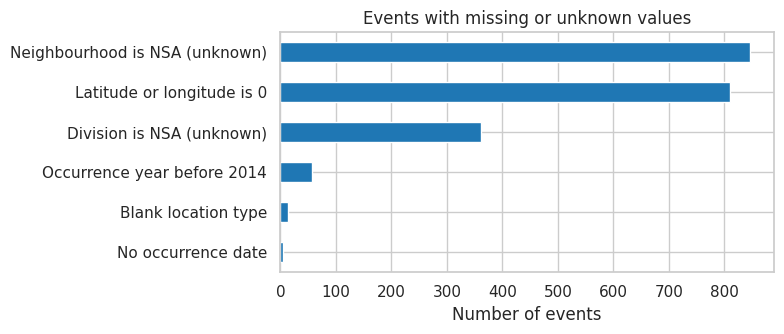

In [9]:
blank = events.isna().sum()
blank = blank[blank > 0]
print("Truly blank values (events):")
display(blank.to_frame("blank_events"))

# Values that are present but really mean "unknown"
hidden = pd.Series({
    "Neighbourhood is NSA (unknown)": (events["NEIGHBOURHOOD_158"] == "NSA").sum(),
    "Division is NSA (unknown)": (events["DIVISION"] == "NSA").sum(),
    "Latitude or longitude is 0": ((events["LAT_WGS84"] == 0) | (events["LONG_WGS84"] == 0)).sum(),
    "Occurrence year before 2014": (events["OCC_YEAR"] < 2014).sum(),
    "No occurrence date": events["OCC_YEAR"].isna().sum(),
    "Blank location type": events["LOCATION_TYPE"].isna().sum(),
})
hidden_table = hidden.to_frame("events")
hidden_table["percent_of_events"] = (hidden / len(events) * 100).round(2)
display(hidden_table)

ax = hidden.sort_values().plot.barh(figsize=(8, 3.5), color="tab:blue")
ax.set_title("Events with missing or unknown values")
ax.set_xlabel("Number of events")
save("02_missing_and_unknown")

### Findings: missing and unknown data

Missing data is small. No column is more than 1.2% unknown.

| Issue | Events | Share of events | What happens to it |
| --- | --- | --- | --- |
| Neighbourhood is NSA (unknown or outside Toronto) | 847 | 1.14% | Dropped in Sean's cleaning: it cannot be assigned to a neighbourhood |
| Latitude or longitude is 0 | 810 | 1.09% | All 810 also have neighbourhood NSA, so they are already dropped |
| Division is NSA | 362 | 0.49% | Not needed: the model uses neighbourhood, not division |
| Occurrence year before 2014 | 57 | 0.08% | Dropped: outside the 2014 to 2026 period |
| No occurrence date | 4 | 0.01% | Dropped: cannot be placed in a month |
| Blank LOCATION_TYPE | 13 | 0.02% | No action: the column is not used (PREMISES_TYPE is used instead) |

Sean's cleaning rules remove 904 events (1.2% of the 74,604 unique events), leaving 73,700. Some events fall in more than one group. The notebook's own independent count (73,700 events kept) matches the total in Sean's panel exactly.

NSA and a coordinate of 0 are not blanks, but the portal documentation says they mean unknown or outside Toronto, so they are counted as missing here.

## 4. Charts from the raw events

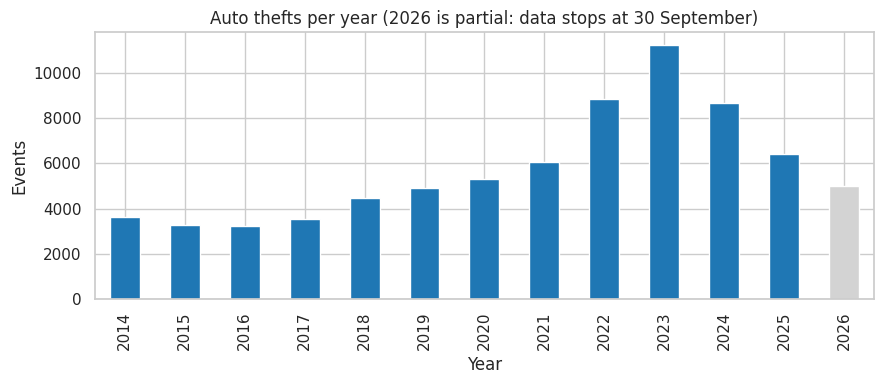

In [10]:
by_year = events[events["OCC_YEAR"] >= 2014]["OCC_YEAR"].astype(int).value_counts().sort_index()
colors = ["tab:blue"] * len(by_year)
colors[-1] = "lightgray"          # 2026 stops at 30 September, so it is a partial year

ax = by_year.plot.bar(color=colors, figsize=(9, 4))
ax.set_title("Auto thefts per year (2026 is partial: data stops at 30 September)")
ax.set_xlabel("Year")
ax.set_ylabel("Events")
save("03_thefts_per_year")

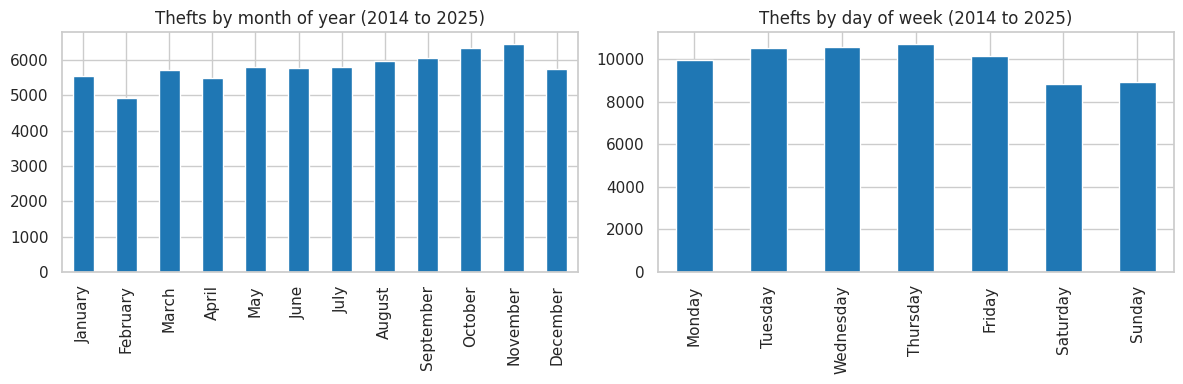

In [11]:
# Month and weekday patterns use full years only (2014 to 2025), so 2026 does not skew them
full_years = events[(events["OCC_YEAR"] >= 2014) & (events["OCC_YEAR"] <= 2025)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
full_years["OCC_MONTH"].value_counts().reindex(MONTHS).plot.bar(ax=axes[0], color="tab:blue")
axes[0].set_title("Thefts by month of year (2014 to 2025)")
axes[0].set_xlabel("")
full_years["OCC_DOW"].value_counts().reindex(DAYS).plot.bar(ax=axes[1], color="tab:blue")
axes[1].set_title("Thefts by day of week (2014 to 2025)")
axes[1].set_xlabel("")
save("04_thefts_by_month_and_weekday")

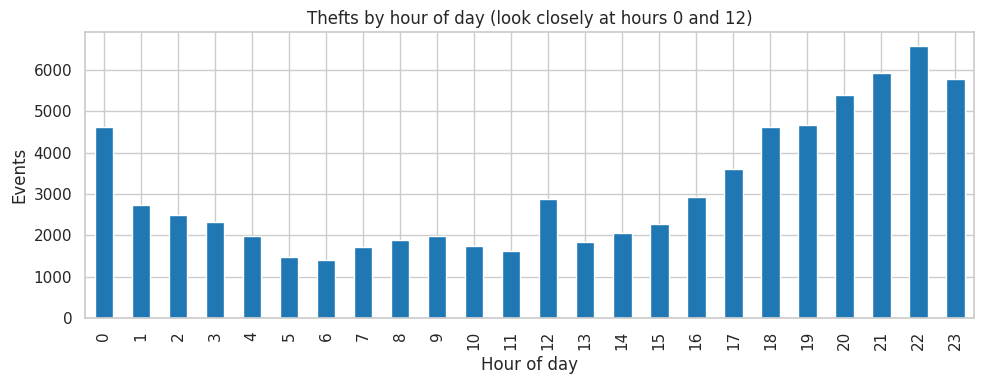

In [12]:
ax = events["OCC_HOUR"].value_counts().sort_index().plot.bar(figsize=(10, 4), color="tab:blue")
ax.set_title("Thefts by hour of day (look closely at hours 0 and 12)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Events")
save("05_thefts_by_hour")

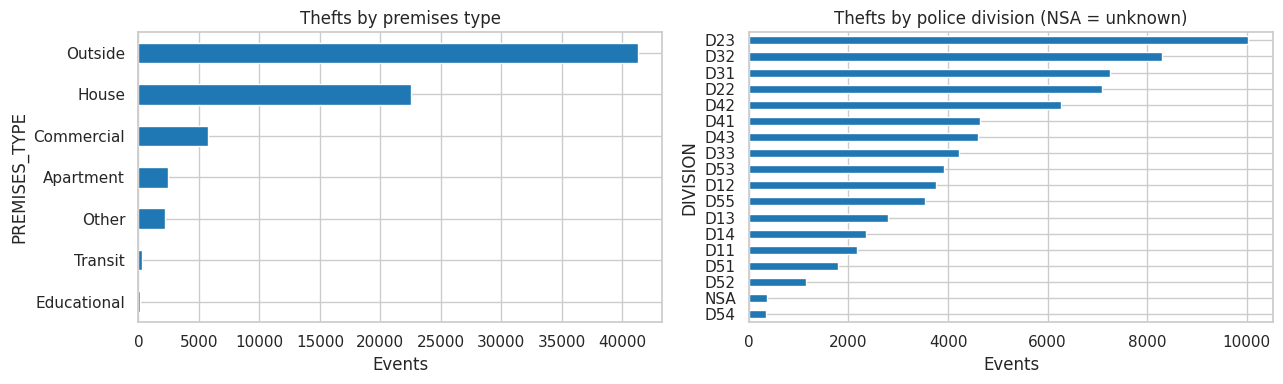

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

events["PREMISES_TYPE"].value_counts().sort_values().plot.barh(ax=axes[0], color="tab:blue")
axes[0].set_title("Thefts by premises type")
axes[0].set_xlabel("Events")

events["DIVISION"].value_counts().sort_values().plot.barh(ax=axes[1], color="tab:blue")
axes[1].set_title("Thefts by police division (NSA = unknown)")
axes[1].set_xlabel("Events")
save("06_premises_and_division")

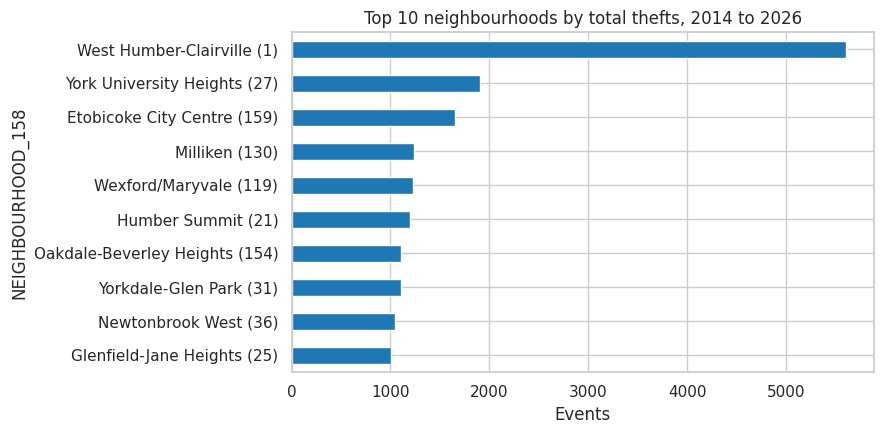

In [14]:
top10 = (events[events["NEIGHBOURHOOD_158"] != "NSA"]["NEIGHBOURHOOD_158"]
         .value_counts().head(10).sort_values())
ax = top10.plot.barh(figsize=(9, 4.5), color="tab:blue")
ax.set_title("Top 10 neighbourhoods by total thefts, 2014 to 2026")
ax.set_xlabel("Events")
save("07_top10_neighbourhoods")

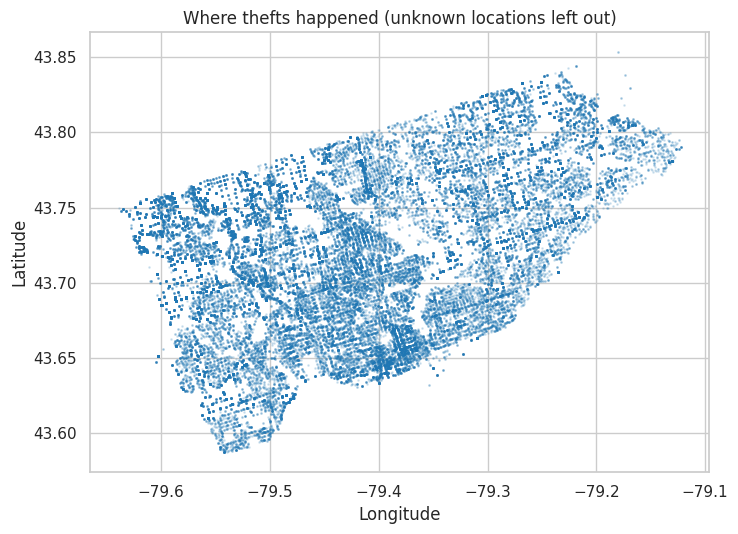

In [15]:
located = events[(events["LAT_WGS84"] != 0) & (events["LONG_WGS84"] != 0)]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(located["LONG_WGS84"], located["LAT_WGS84"], s=1, alpha=0.15, color="tab:blue")
ax.set_title("Where thefts happened (unknown locations left out)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect(1 / np.cos(np.radians(43.7)))   # keeps Toronto's shape roughly correct
save("08_location_map")

### Findings: charts from the raw events

- **Thefts per year.** There were 3,603 events in 2014 and 3,235 in 2016, then a rise every year to 11,260 in 2023 (3.1 times 2014), followed by a fall to 8,672 in 2024 and 6,424 in 2025. 2026 shows 4,983 events but only runs to 30 September. The years 2022 to 2024 hold 38.6% of all events since 2014. *Why it matters:* the overall level moves a lot, so the hotspot label is ranked within each month and year should not be used as a feature.
- **Month and weekday.** The pattern is modest. November is the busiest month (6,453 events) and February the quietest (4,909, and it has fewer days), a ratio of 1.3. Weekdays are busier than weekends: Thursday has 10,714 events and Saturday 8,823 (full years 2014 to 2025). *Why it matters:* seasonality is mild, so month features may add little, and weekday does not apply to monthly counts.
- **Hour of day.** Thefts peak at 22:00 (6,588 events) and are lowest at 06:00 (1,405). Hours 18 to 23 hold 44.2% of events, and 22:00 to 05:59 holds 37.5%. Two hours stand out: hour 0 has 4,616 events against 2,724 at hour 1, and hour 12 has 2,889 against 1,618 at hour 11 and 1,845 at hour 13. These spikes may be estimated or default times when the real time is unknown. *Why it matters:* only the night-share feature uses the hour, so that feature is noisier than it looks and should be stated as a limitation.
- **Premises type and division.** Outside is 55.3% of events, House 30.2%, Commercial 7.8%, Apartment 3.3%, Other 3.0%, Transit 0.4% and Educational 0.1%. Division D23 is the busiest at 13.4%, followed by D32 (11.1%) and D31 (9.7%). *Why it matters:* the premises mix becomes the house-share and outside-share features. Division is not used because neighbourhood is more detailed.
- **Top 10 neighbourhoods.** West Humber-Clairville (1) has 5,604 events, 7.5% of all events and almost three times the next neighbourhood (York University Heights, 1,904). The top 10 hold 22.9% of events while being 6.3% of the 158 neighbourhoods. The median neighbourhood has 363 events in total. *Why it matters:* thefts are concentrated, which helps explain why some neighbourhoods are almost always hotspots, and results should be checked so that a few neighbourhoods do not drive everything.
- **Location map.** Thefts occur across the whole city with no empty area. The grid-like pattern comes from locations being offset to intersections, and heavily overlapping points hide how many thefts sit in each spot, so the map shows spread rather than intensity. The 810 events with unknown location are left out.

## 5. Charts from the neighbourhood-by-month table

The model works on counts per neighbourhood per month, so these charts matter most. The next cell recounts the cleaned events on its own, as a check. Every chart after that uses Sean's `data/panel.csv`.

In [16]:
# Independent check only. The charts below use data/panel.csv, not this table.
good = (events[(events["NEIGHBOURHOOD_158"] != "NSA") & (events["OCC_YEAR"] >= 2014)]
        .dropna(subset=["OCC_YEAR", "OCC_MONTH"]).copy())

month_num = {m: i + 1 for i, m in enumerate(MONTHS)}
good["month"] = pd.to_datetime({"year": good["OCC_YEAR"].astype(int),
                                "month": good["OCC_MONTH"].map(month_num).astype(int),
                                "day": 1}).dt.to_period("M")
good = good[good["month"] <= pd.Period("2026-09", freq="M")]
print("Events kept:", len(good), "| dropped:", len(events) - len(good))

# One row per neighbourhood, one column per month, with 0 for months with no theft
all_months = pd.period_range("2014-01", "2026-09", freq="M")
hoods = sorted(good["NEIGHBOURHOOD_158"].unique())
check_panel = (good.groupby(["NEIGHBOURHOOD_158", "month"]).size().unstack(fill_value=0)
               .reindex(index=hoods, columns=all_months, fill_value=0))

print(f"Check grid: {check_panel.shape[0]} neighbourhoods x {check_panel.shape[1]} months = {check_panel.size:,} cells")
print(f"Cells with zero thefts: {(check_panel.values == 0).mean():.1%}")
check_panel.iloc[:5, :6]

Events kept: 73700 | dropped: 904
Check grid: 158 neighbourhoods x 153 months = 24,174 cells
Cells with zero thefts: 19.9%


,2014-01,2014-02,2014-03,2014-04,2014-05,2014-06
NEIGHBOURHOOD_158,,,,,,
Agincourt North (129),2,1,1,1,0,2
Agincourt South-Malvern West (128),5,0,1,3,2,3
Alderwood (20),0,1,3,0,1,0
Annex (95),0,2,0,2,2,3
Avondale (153),1,0,0,1,3,0


**Charts use Sean's panel.** `data/panel.csv` stores one row per neighbourhood per month. The cell below pivots it to one row per neighbourhood and one column per month, which is the shape the charts expect.

In [17]:
sean = pd.read_csv(f"{REPO}/data/panel.csv", parse_dates=["MONTH_START"])
panel = sean.pivot(index="HOOD_158", columns="MONTH_START", values="theft_count")
panel.columns = panel.columns.to_period("M")
print("Using Sean's panel:", panel.shape)
print("Total thefts in the panel:", int(panel.values.sum()))

Using Sean's panel: (158, 153)
Total thefts in the panel: 73700


Median: 2.0 | mean: 3.05 | max: 91


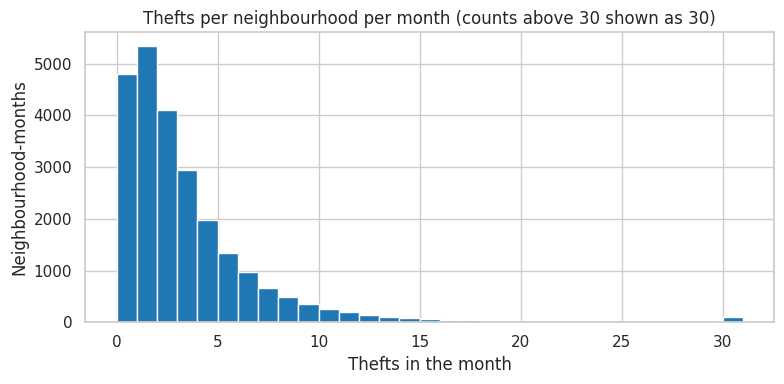

In [18]:
counts = panel.values.ravel()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(np.clip(counts, 0, 30), bins=range(0, 32), color="tab:blue")
ax.set_title("Thefts per neighbourhood per month (counts above 30 shown as 30)")
ax.set_xlabel("Thefts in the month")
ax.set_ylabel("Neighbourhood-months")
print("Median:", np.median(counts), "| mean:", counts.mean().round(2), "| max:", counts.max())
save("09_distribution_of_monthly_counts")

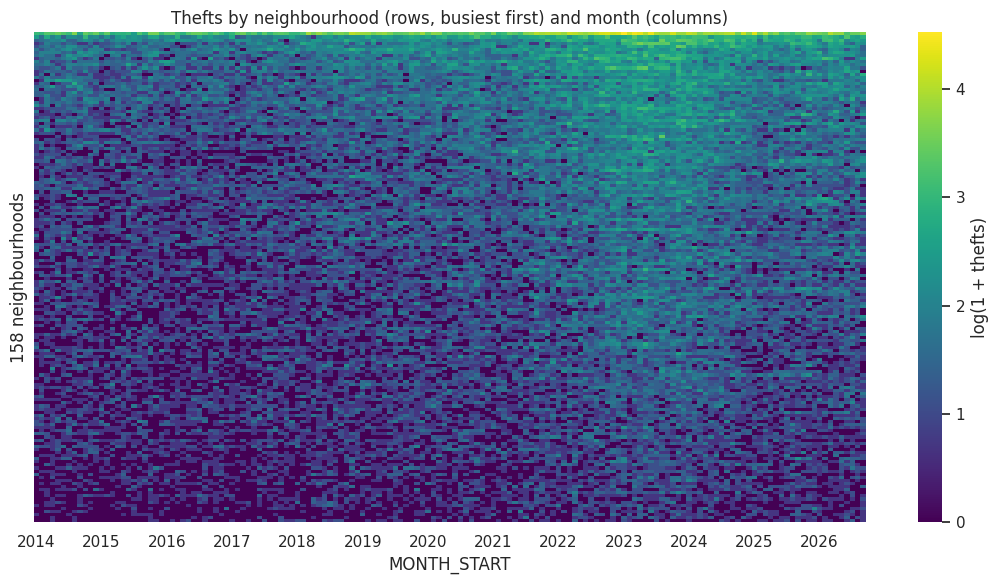

In [19]:
order = panel.sum(axis=1).sort_values(ascending=False).index   # busiest neighbourhoods at the top

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(np.log1p(panel.loc[order]), cmap="viridis", yticklabels=False, xticklabels=False,
            cbar_kws={"label": "log(1 + thefts)"}, ax=ax)
months = list(panel.columns)
jan = [i for i, m in enumerate(months) if m.month == 1]
ax.set_xticks([i + 0.5 for i in jan])
ax.set_xticklabels([months[i].year for i in jan], rotation=0)
ax.set_title("Thefts by neighbourhood (rows, busiest first) and month (columns)")
ax.set_ylabel("158 neighbourhoods")
save("10_neighbourhood_by_month_heatmap")

Hotspot share: 30.6%  (22,120 neighbourhood-months)


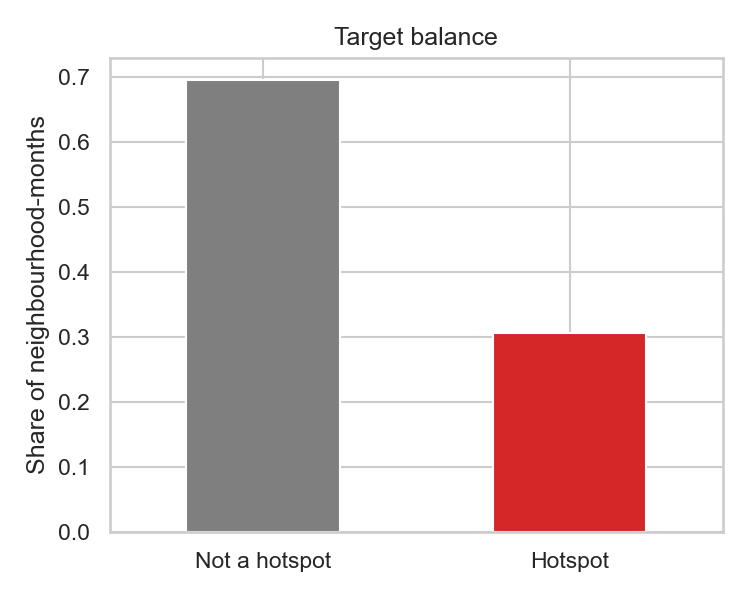

In [20]:
# Same hotspot rule as the panel: top 25% of neighbourhoods next month, ties included.
this_month = panel.T                          # rows = months, columns = neighbourhoods
next_month = this_month.shift(-1)             # the same neighbourhood one month later
cutoff = next_month.quantile(0.75, axis=1)    # 75th percentile across the 158 neighbourhoods, per month
hot = next_month.ge(cutoff, axis=0)           # True = at or above the cutoff
hot = hot.iloc[:-1]                           # the last month has no "next month"
hot = hot.loc["2015-01":]                     # the first 12 months only supply history for rolling averages

share = hot.values.mean()
print(f"Hotspot share: {share:.1%}  ({hot.size:,} neighbourhood-months)")

ax = pd.Series({"Not a hotspot": 1 - share, "Hotspot": share}).plot.bar(figsize=(5, 4), color=["tab:gray", "tab:red"])
ax.set_title("Target balance")
ax.set_ylabel("Share of neighbourhood-months")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
save("11_target_balance")

MONTH_START
2014    2.75
2015    2.00
2016    2.00
2017    2.75
2018    3.00
2019    3.00
2020    4.00
2021    4.00
2022    6.00
2023    8.00
2024    6.00
2025    4.00
2026    5.00
Name: 0.75, dtype: float64


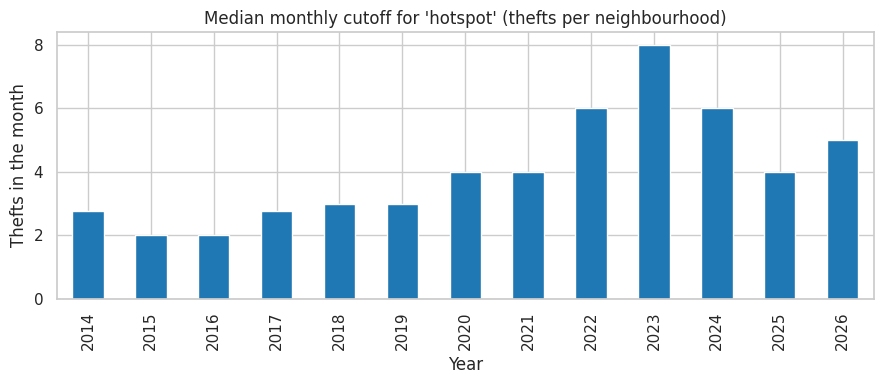

In [21]:
# How big is the cutoff? (the number of thefts a neighbourhood needs to count as a hotspot)
cut = cutoff.dropna().copy()
cut.index = cut.index + 1                      # label each cutoff with the month it applies to
cut_by_year = cut.groupby(cut.index.year).median()
print(cut_by_year)

ax = cut_by_year.plot.bar(figsize=(9, 4), color="tab:blue")
ax.set_title("Median monthly cutoff for 'hotspot' (thefts per neighbourhood)")
ax.set_xlabel("Year")
ax.set_ylabel("Thefts in the month")
save("12_hotspot_cutoff_by_year")

Hotspot in at least 80% of months: 11 neighbourhoods
Hotspot in at most 20% of months:  74 neighbourhoods
In between (they swing):           73 neighbourhoods


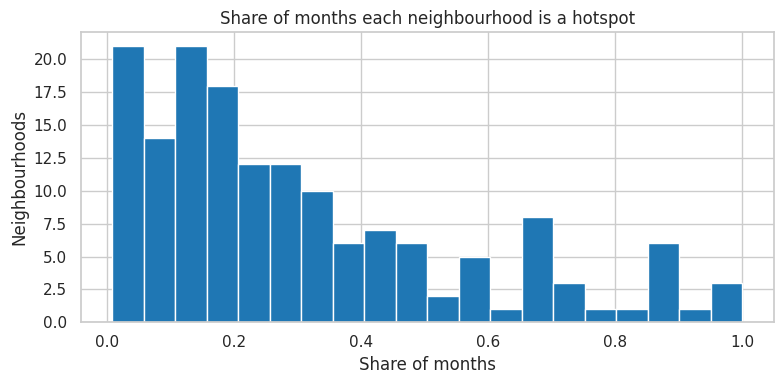

In [22]:
# How often is each neighbourhood a hotspot?
freq = hot.mean()
always = int((freq >= 0.8).sum())
rarely = int((freq <= 0.2).sum())
print(f"Hotspot in at least 80% of months: {always} neighbourhoods")
print(f"Hotspot in at most 20% of months:  {rarely} neighbourhoods")
print(f"In between (they swing):           {len(freq) - always - rarely} neighbourhoods")

ax = freq.plot.hist(bins=20, figsize=(8, 4), color="tab:blue")
ax.set_title("Share of months each neighbourhood is a hotspot")
ax.set_xlabel("Share of months")
ax.set_ylabel("Neighbourhoods")
save("13_hotspot_frequency_per_neighbourhood")

Correlation of this month's count with next month's:
  Pearson:  0.795
  Spearman: 0.535


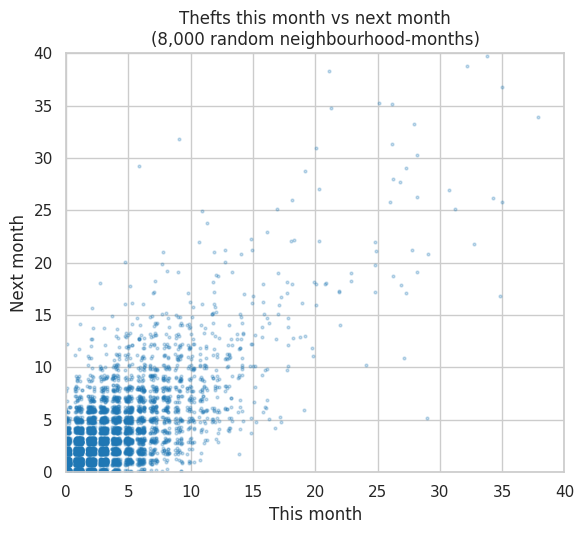

In [23]:
# This month versus next month
pairs = pd.DataFrame({"this_month": this_month.stack(), "next_month": next_month.stack()}).dropna()

print("Correlation of this month's count with next month's:")
print("  Pearson: ", round(pairs.corr().iloc[0, 1], 3))
print("  Spearman:", round(pairs.corr(method="spearman").iloc[0, 1], 3))

rng = np.random.default_rng(1)
sample = pairs.sample(8000, random_state=1)
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(sample["this_month"] + rng.uniform(-0.3, 0.3, len(sample)),
           sample["next_month"] + rng.uniform(-0.3, 0.3, len(sample)),
           s=4, alpha=0.25, color="tab:blue")
ax.set_xlim(0, 40)
ax.set_ylim(0, 40)
ax.set_title("Thefts this month vs next month\n(8,000 random neighbourhood-months)")
ax.set_xlabel("This month")
ax.set_ylabel("Next month")
save("14_this_month_vs_next_month")

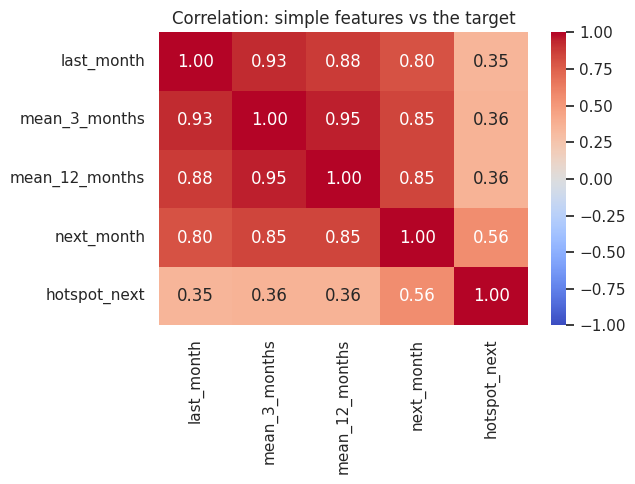

In [24]:
# Simple features against next month's count and the hotspot label
hot_long = hot.stack().astype(int).rename("hotspot_next")
feat = pd.DataFrame({
    "last_month": this_month.stack(),
    "mean_3_months": this_month.rolling(3).mean().stack(),
    "mean_12_months": this_month.rolling(12).mean().stack(),
    "next_month": next_month.stack(),
}).dropna().join(hot_long, how="inner")

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(feat.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation: simple features vs the target")
save("15_correlation_simple_features")

,rows,first_forecast_month,last_forecast_month,hotspot_share
train,13114,2015-02,2021-12,0.319
validation,3792,2022-01,2023-12,0.28
test,5214,2024-01,2026-09,0.29


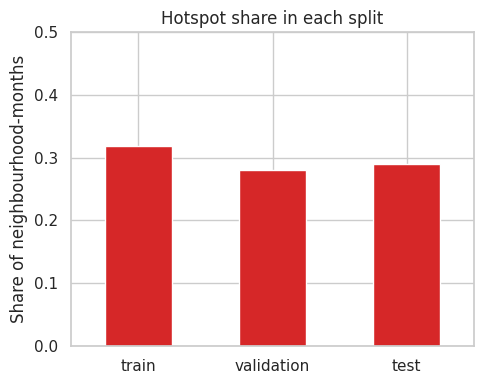

In [25]:
# Hotspot share in Sean's train, validation and test files (uses the local project data files)
files = {name: f"{REPO}/data/{name}.csv" for name in ["train", "validation", "test"]}

if all(os.path.exists(path) for path in files.values()):
    summary = {}
    for name, path in files.items():
        part = pd.read_csv(path)
        summary[name] = {"rows": len(part),
                         "first_forecast_month": part["forecast_month"].min(),
                         "last_forecast_month": part["forecast_month"].max(),
                         "hotspot_share": round(part["hotspot_next_month"].mean(), 3)}
    split_table = pd.DataFrame(summary).T
    display(split_table)

    ax = split_table["hotspot_share"].astype(float).plot.bar(figsize=(5, 4), color="tab:red")
    ax.set_title("Hotspot share in each split")
    ax.set_ylabel("Share of neighbourhood-months")
    ax.set_ylim(0, 0.5)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    save("16_hotspot_share_by_split")
else:
    print("Train, validation, or test file was not found in data/.")

In [26]:
print("Charts are saved in:", CHARTS_DIR)


  adding: charts/ (stored 0%)
  adding: charts/11_target_balance.png (deflated 17%)
  adding: charts/03_thefts_per_year.png (deflated 24%)
  adding: charts/05_thefts_by_hour.png (deflated 22%)
  adding: charts/16_hotspot_share_by_split.png (deflated 18%)
  adding: charts/08_location_map.png (deflated 2%)
  adding: charts/10_neighbourhood_by_month_heatmap.png (deflated 9%)
  adding: charts/14_this_month_vs_next_month.png (deflated 6%)
  adding: charts/06_premises_and_division.png (deflated 20%)
  adding: charts/13_hotspot_frequency_per_neighbourhood.png (deflated 18%)
  adding: charts/04_thefts_by_month_and_weekday.png (deflated 17%)
  adding: charts/15_correlation_simple_features.png (deflated 10%)
  adding: charts/01_correlation_raw_numeric.png (deflated 9%)
  adding: charts/02_missing_and_unknown.png (deflated 16%)
  adding: charts/09_distribution_of_monthly_counts.png (deflated 19%)
  adding: charts/07_top10_neighbourhoods.png (deflated 15%)
  adding: charts/12_hotspot_cutoff_by_yea

### Findings: charts from the neighbourhood-by-month table

- **Distribution of monthly counts.** The median neighbourhood-month has 2 thefts (mean 3.05, maximum 91). 19.9% of cells are zero, 59.0% are 0 to 2, 84.8% are 5 or fewer, and only 4.9% reach 10 or more. *Why it matters:* counts are small and noisy, so a change of one or two thefts can move a neighbourhood across the hotspot line.
- **Heatmap.** The busiest neighbourhoods stay bright across the years, and the overall brightness rises from about 2022, peaks in 2023 and then fades. The citywide monthly total ranges from 200 thefts (February 2015) to 1,060 (May 2023), and the average month had about 296 thefts in 2014, 927 in 2023 and 530 in 2025.
- **Target balance.** 30.6% of the 22,120 neighbourhood-months are hotspots. That is above 25% because tied counts at the cutoff are all labelled hotspots, so Sean's panel has between 40 and 71 hotspots per month rather than exactly 40.
- **Hotspot cutoff by year.** The number of thefts needed to be a hotspot changes: about 2 in 2015 and 2016, 3 in 2017 to 2019, 4 in 2020 and 2021, 6 in 2022, 8 in 2023, then 6, 4 and 5 in 2024 to 2026. *Why it matters:* in early years a "hotspot" means as few as 2 thefts in a month, so early labels are noisier than later ones.
- **How often each neighbourhood is a hotspot.** 11 neighbourhoods are hotspots in at least 80% of months, 74 in at most 20% of months, and 73 swing in between. *Why it matters:* most neighbourhoods are easy to call, and the model's real value is in the 73 that swing.
- **This month versus next month.** The correlation between a neighbourhood's count this month and next month is 0.795 (Pearson) and 0.535 (Spearman). The rank correlation is lower because most cells are small tied counts, while a few busy neighbourhoods lift the Pearson value. In the simple-feature correlation chart, next month's count correlates 0.80 with last month's and 0.85 with both the 3-month and 12-month averages. The simple features correlate 0.35 to 0.36 with the hotspot label (the 0.56 for next month's count is the outcome itself and is not a feature). *Why it matters:* recent history already carries much of the signal, so a simple "same as recent months" rule is a strong baseline that the model must be compared against.
- **Train, validation and test split (Sean's files).** The hotspot share is 31.9% in train (13,114 rows, forecasts from February 2015 to December 2021), 28.0% in validation (3,792 rows, 2022 to 2023) and 29.0% in test (5,214 rows, January 2024 to September 2026). *Why it matters:* the class mix is similar across the splits, and splitting in time order stops the model from learning from the future. Predicting "not a hotspot" every time would be right about 71% of the time in the test months, so accuracy alone would mislead.

## 6. Findings log and handoffs

This table summarizes the findings above. It feeds the "Data exploration and findings" section of the report, and the third column is what Sean and Emine need to hear.

| Finding | Evidence (chart or number) | Why it matters for the model |
| --- | --- | --- |
| Thefts rose sharply, then fell | 3,603 events in 2014, 11,260 in 2023 and 6,424 in 2025 (chart 03). Citywide monthly total from 200 (Feb 2015) to 1,060 (May 2023). | The overall level swings, so the hotspot label is ranked within each month and year should not be a model feature. |
| Hotspot status is persistent | Last month's count correlates 0.80 with next month's. 11 neighbourhoods are hotspots in 80% or more of months and 74 in 20% or fewer (charts 13, 14, 15). | Recent history is a strong baseline. Rolling averages and rank features come first, and the model must be compared with a simple "same as recently" rule. |
| 73 neighbourhoods swing | 73 of 158 are hotspots in 20% to 80% of months (chart 13). | This is where the model adds value, so evaluate it on these neighbourhoods as well as overall. |
| Counts are small and noisy | Median 2 thefts per neighbourhood-month. 59.0% of cells are 0 to 2. The hotspot cutoff is 2 in 2015 and 2016 but 8 in 2023 (charts 09, 12). | Early-year labels are noisy. Compare training from 2015 and from 2018 (Sean's script does this on the validation data). |
| Moderate class imbalance | 30.6% hotspots overall. 31.9% in train, 28.0% in validation, 29.0% in test (charts 11, 16). | Accuracy misleads, because "never a hotspot" is right about 71% of test months. Use F1, recall and ROC AUC, and try class weights. |
| Thefts are concentrated | West Humber-Clairville (1) has 5,604 events (7.5%). The top 10 neighbourhoods hold 22.9% of events (chart 07). | A few neighbourhoods dominate the totals, so check that results are not driven by them alone. |
| Hour data has spikes at 0 and 12 | 4,616 events at hour 0 against 2,724 at hour 1. 2,889 at hour 12 against 1,618 at hour 11 (chart 05). | Only the night-share feature uses the hour, so treat it with care and state the limitation. |
| The cleaned data checks out | 8,142 duplicate rows removed. 904 events (1.2%) dropped. This notebook's own count of 73,700 events matches Sean's panel total exactly. | The panel can be trusted as the base for features and models. |

**Tools and libraries used (for the report):** Python, pandas, numpy, matplotlib, seaborn, run in Google Colab.

**Files this notebook uses and produces:** it reads `data/data_dictionary.csv` and writes the 16 charts to `data/charts/`.